In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Convert TotalCharges to numeric; blank values become NaN, then fill with 0.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# overall churn rate

In [3]:
total_customers = len(df)
churned_customers = (df["Churn"] == "Yes").sum()
retained_customers = (df["Churn"] == "No").sum()
churn_rate = churned_customers / total_customers * 100

print("Total customers:", total_customers)
print("Churned customers:", churned_customers)
print("Retained customers:", retained_customers)
print(f"Overall churn rate: {churn_rate:.2f}%")

Total customers: 7043
Churned customers: 1869
Retained customers: 5174
Overall churn rate: 26.54%


# churn by contract type

Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn Rate (%), dtype: float64

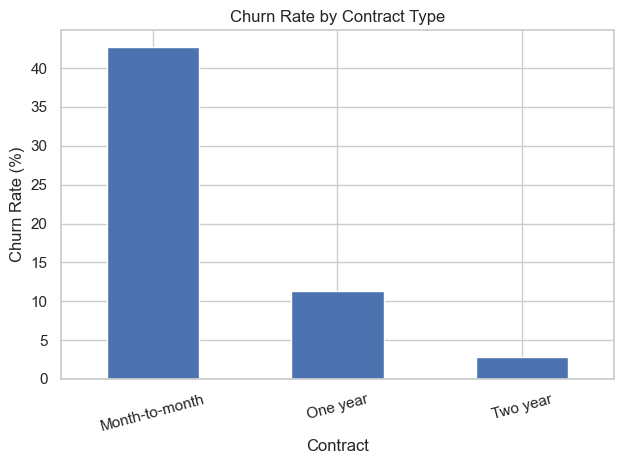

In [4]:
contract = df.groupby("Contract")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
).sort_values(ascending=False)

display(contract.round(2).rename("Churn Rate (%)"))
contract.plot(kind="bar", title="Churn Rate by Contract Type", ylabel="Churn Rate (%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# churn by customer tenure

TenureGroup
0-12     47.44
13-24    28.71
25-48    20.39
49-72     9.51
Name: Churn Rate (%), dtype: float64

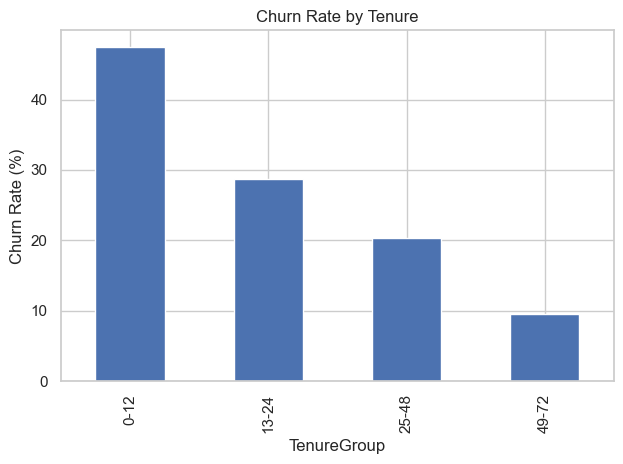

In [5]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12", "13-24", "25-48", "49-72"]
)

tenure = df.groupby("TenureGroup", observed=False)["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
)

display(tenure.round(2).rename("Churn Rate (%)"))
tenure.plot(kind="bar", title="Churn Rate by Tenure", ylabel="Churn Rate (%)")
plt.tight_layout()
plt.show()

# monthly charges by churn status

,mean,median
Churn,,
No,61.27,64.43
Yes,74.44,79.65


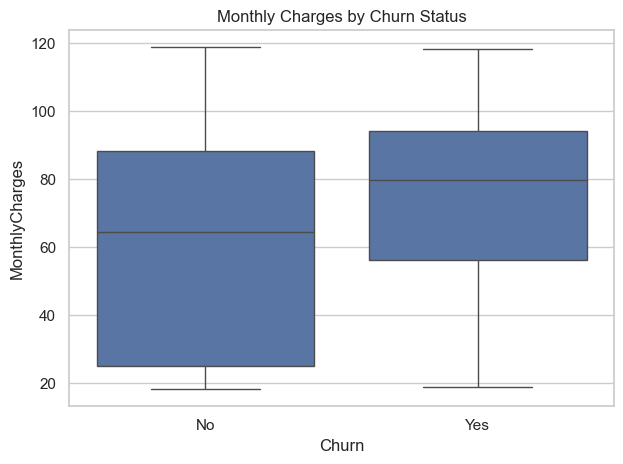

In [6]:
display(df.groupby("Churn")["MonthlyCharges"].agg(["mean", "median"]).round(2))

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges by Churn Status")
plt.tight_layout()
plt.show()

# churn by technical support

TechSupport
No     41.64
Yes    15.17
Name: Churn Rate (%), dtype: float64

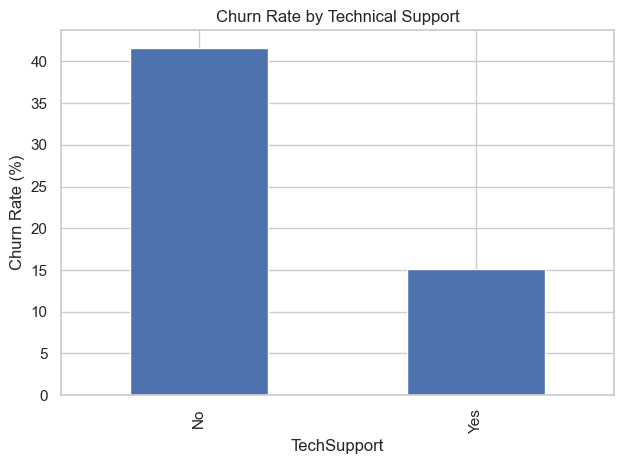

In [7]:
support_df = df[df["TechSupport"].isin(["Yes", "No"])]
support = support_df.groupby("TechSupport")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
)

display(support.round(2).rename("Churn Rate (%)"))
support.plot(kind="bar", title="Churn Rate by Technical Support", ylabel="Churn Rate (%)")
plt.tight_layout()
plt.show()

# key finding summary

In [8]:
print("CUSTOMER CHURN & RETENTION — KEY FINDINGS")
print("-" * 45)
print(f"1. Overall churn rate: {churn_rate:.2f}% ({churned_customers:,} of {total_customers:,} customers).")
print(f"2. Contract type with highest churn: {contract.idxmax()} ({contract.max():.2f}%).")
print(f"3. Tenure group with highest churn: {tenure.idxmax()} ({tenure.max():.2f}%).")
medians = df.groupby("Churn")["MonthlyCharges"].median()
print(f"4. Median monthly charges — churned: {medians.get('Yes', float('nan')):.2f}; retained: {medians.get('No', float('nan')):.2f}.")
print("Technical support churn rates (%):")
print(support.round(2))

print("\nInterpret the results using the actual values above. These patterns show associations, not necessarily causes.")

CUSTOMER CHURN & RETENTION — KEY FINDINGS
---------------------------------------------
1. Overall churn rate: 26.54% (1,869 of 7,043 customers).
2. Contract type with highest churn: Month-to-month (42.71%).
3. Tenure group with highest churn: 0-12 (47.44%).
4. Median monthly charges — churned: 79.65; retained: 64.43.
Technical support churn rates (%):
TechSupport
No     41.64
Yes    15.17
Name: Churn, dtype: float64

Interpret the results using the actual values above. These patterns show associations, not necessarily causes.
